# Plot treatment cytotoxicity inferences
`4.infer_binary_mlp_control.ipynb` scored every cell, across all treatments and patients, with each patient's trained DMSO-vs-Staurosporine MLP classifier, producing per-cell `Metadata_predicted_cytotoxic_probability` (P(cytotoxic-like)) and `Metadata_distance_from_dmso_centroid`.

This notebook visualizes those scores:
1. Distribution of P(cytotoxic) per treatment, across all cells.
2. P(cytotoxic) vs. distance-from-DMSO, faceted by treatment - cells that are far from DMSO but not predicted cytotoxic are candidates for a treatment-specific, non-toxic morphological response.
3. A patient x treatment heatmap of mean P(cytotoxic), analogous to the viability heatmaps in `5.differential_analysis`.

In [1]:
list_of_packages <- c("ggplot2", "dplyr", "arrow", "ggrastr", "RColorBrewer")
for (package in list_of_packages) {
    suppressPackageStartupMessages(
        suppressWarnings(
            library(package, character.only = TRUE, quietly = TRUE, warn.conflicts = FALSE)
        )
    )
}

find_git_root <- function() {
    cwd <- getwd()
    if (dir.exists(file.path(cwd, ".git"))) {
        return(cwd)
    }
    current_path <- cwd
    while (dirname(current_path) != current_path) {
        parent_path <- dirname(current_path)
        if (dir.exists(file.path(parent_path, ".git"))) {
            return(parent_path)
        }
        current_path <- parent_path
    }
    stop("No Git root directory found.")
}

root_dir <- find_git_root()
source(file.path(root_dir, "utils", "r_plot_themes.r"))

In [2]:
results_dir <- file.path(root_dir, "6.treatment_predictive_model", "model_results")
figures_dir <- file.path(root_dir, "6.treatment_predictive_model", "figures")
dir.create(figures_dir, recursive = TRUE, showWarnings = FALSE)

inference_path <- file.path(results_dir, "binary_mlp_control_all_treatments_inference.parquet")
per_treatment_summary_path <- file.path(results_dir, "binary_mlp_control_per_treatment_summary.parquet")
per_patient_treatment_summary_path <- file.path(
    results_dir, "binary_mlp_control_per_patient_treatment_summary.parquet"
)

distribution_figure_path <- file.path(figures_dir, "binary_mlp_control_probability_by_treatment.png")
scatter_figure_path <- file.path(figures_dir, "binary_mlp_control_probability_vs_dmso_distance.png")
heatmap_figure_path <- file.path(figures_dir, "binary_mlp_control_heatmap.png")

In [3]:
inference_df <- read_parquet(inference_path)
per_treatment_summary_df <- read_parquet(per_treatment_summary_path)
per_patient_treatment_summary_df <- read_parquet(per_patient_treatment_summary_path)

treatment_levels <- intersect(
    custom_treatment_order, unique(inference_df$Metadata_Experiment_Treatment)
)
inference_df$Metadata_Experiment_Treatment <- factor(
    inference_df$Metadata_Experiment_Treatment, levels = treatment_levels
)
per_treatment_summary_df$Metadata_Experiment_Treatment <- factor(
    per_treatment_summary_df$Metadata_Experiment_Treatment, levels = treatment_levels
)
per_patient_treatment_summary_df$Metadata_Experiment_Treatment <- factor(
    per_patient_treatment_summary_df$Metadata_Experiment_Treatment, levels = treatment_levels
)

head(inference_df)

Metadata_Biology_PatientTumor,Metadata_Experiment_Treatment,Metadata_Experiment_Dose,Metadata_predicted_cytotoxic_probability,Metadata_distance_from_dmso_centroid
<chr>,<fct>,<dbl>,<dbl>,<dbl>
NF0014_T1,Fimepinostat,1,0.6505678,24.42022
NF0014_T1,Fimepinostat,1,0.9775758,29.53514
NF0014_T1,Fimepinostat,1,0.1892724,23.04383
NF0014_T1,Fimepinostat,1,0.9754636,31.26631
NF0014_T1,Fimepinostat,1,0.6903614,30.87837
NF0014_T1,Fimepinostat,1,0.3204210,29.86195


## 1. Predicted cytotoxic probability by treatment
Every scored cell, grouped by treatment (ordered/colored by the shared `custom_treatment_order` / `custom_treatment_palette`). `DMSO` and `Staurosporine` are the training controls and anchor the low/high ends.

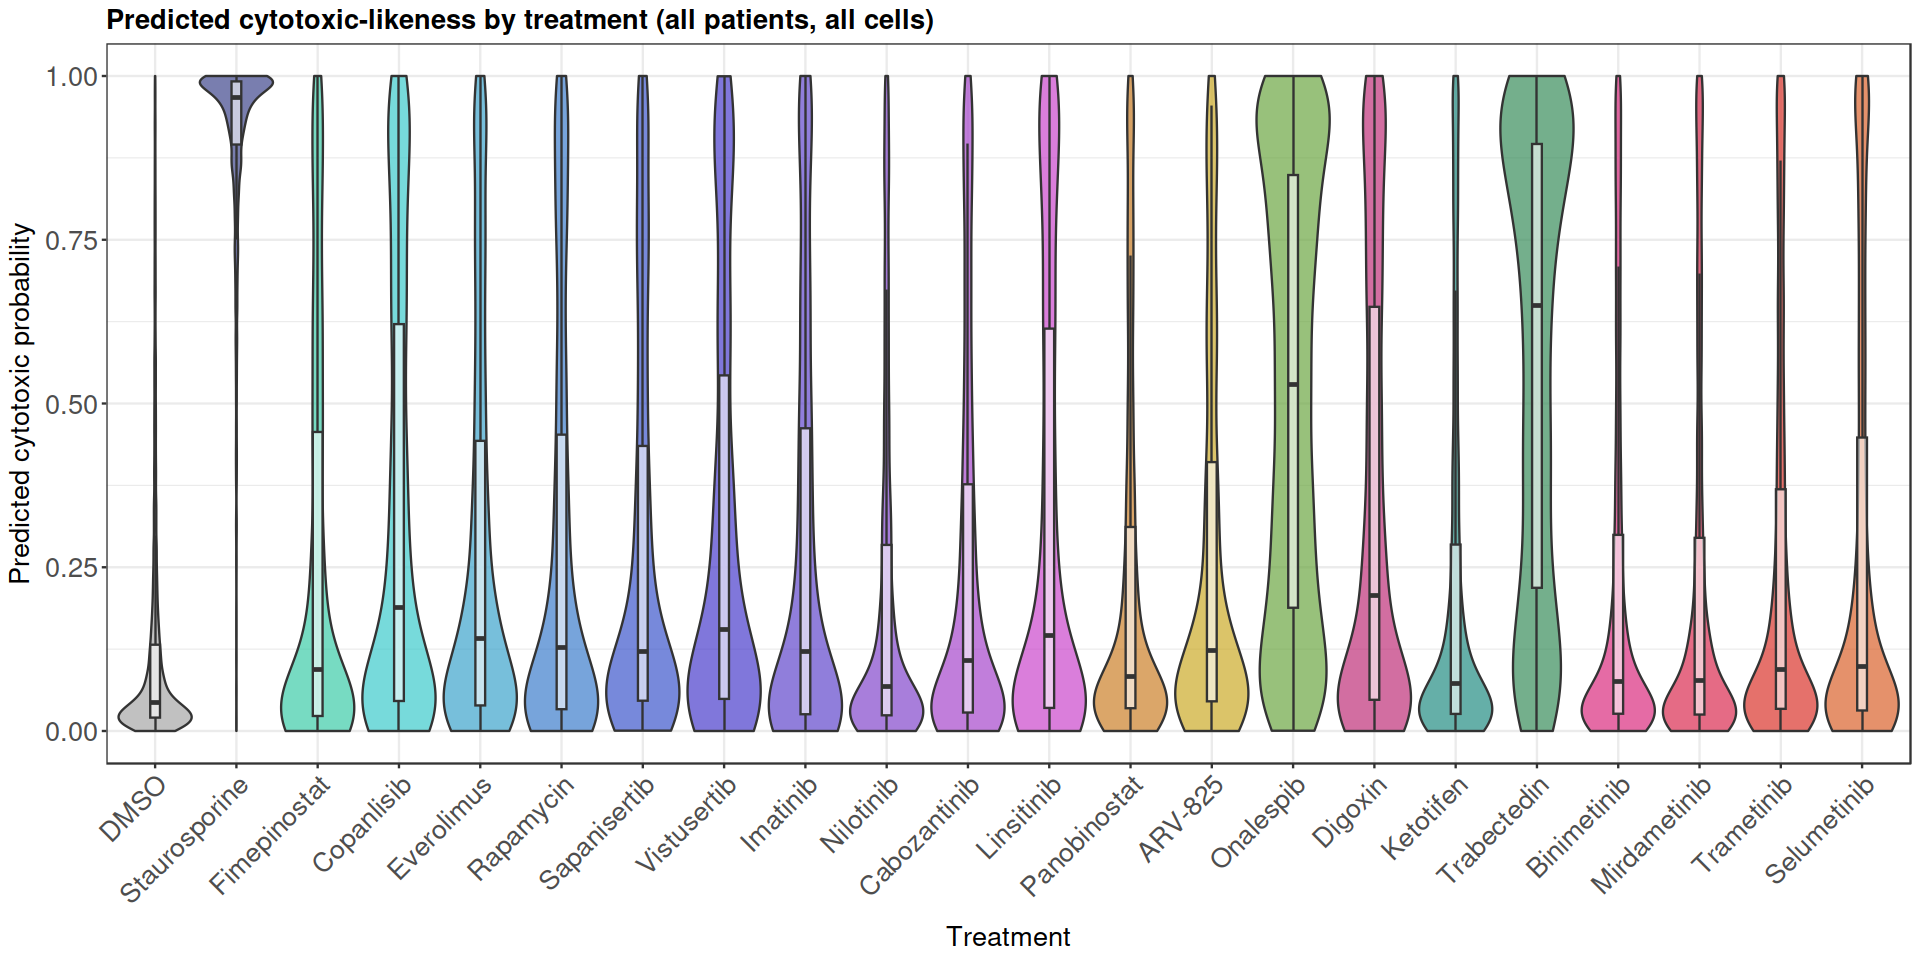

In [4]:
options(repr.plot.width = 16, repr.plot.height = 8)

probability_by_treatment_plot <- (
    ggplot(
        inference_df,
        aes(x = Metadata_Experiment_Treatment, y = Metadata_predicted_cytotoxic_probability)
    )
    + geom_violin(aes(fill = Metadata_Experiment_Treatment), scale = "width", alpha = 0.7)
    + geom_boxplot(width = 0.12, outlier.shape = NA, fill = "white", alpha = 0.6)
    + scale_fill_manual(values = custom_treatment_palette, guide = "none")
    + labs(
        x = "Treatment",
        y = "Predicted cytotoxic probability",
        title = "Predicted cytotoxic-likeness by treatment (all patients, all cells)"
    )
    + theme_manuscript(base_size = 16, x_text = "angled")
)

ggsave(
    distribution_figure_path, probability_by_treatment_plot,
    width = 16, height = 8, dpi = 600, bg = "white"
)
probability_by_treatment_plot

## 2. Predicted cytotoxic probability vs. distance from the DMSO centroid
Faceted by treatment. The top-left region of each panel (far from DMSO, low predicted cytotoxic probability) holds the candidate treatment-specific, non-toxic responders described in `1.train_binary_mlp_control.ipynb`'s goal. Points are rasterized (`ggrastr`) since there are tens of thousands of cells.

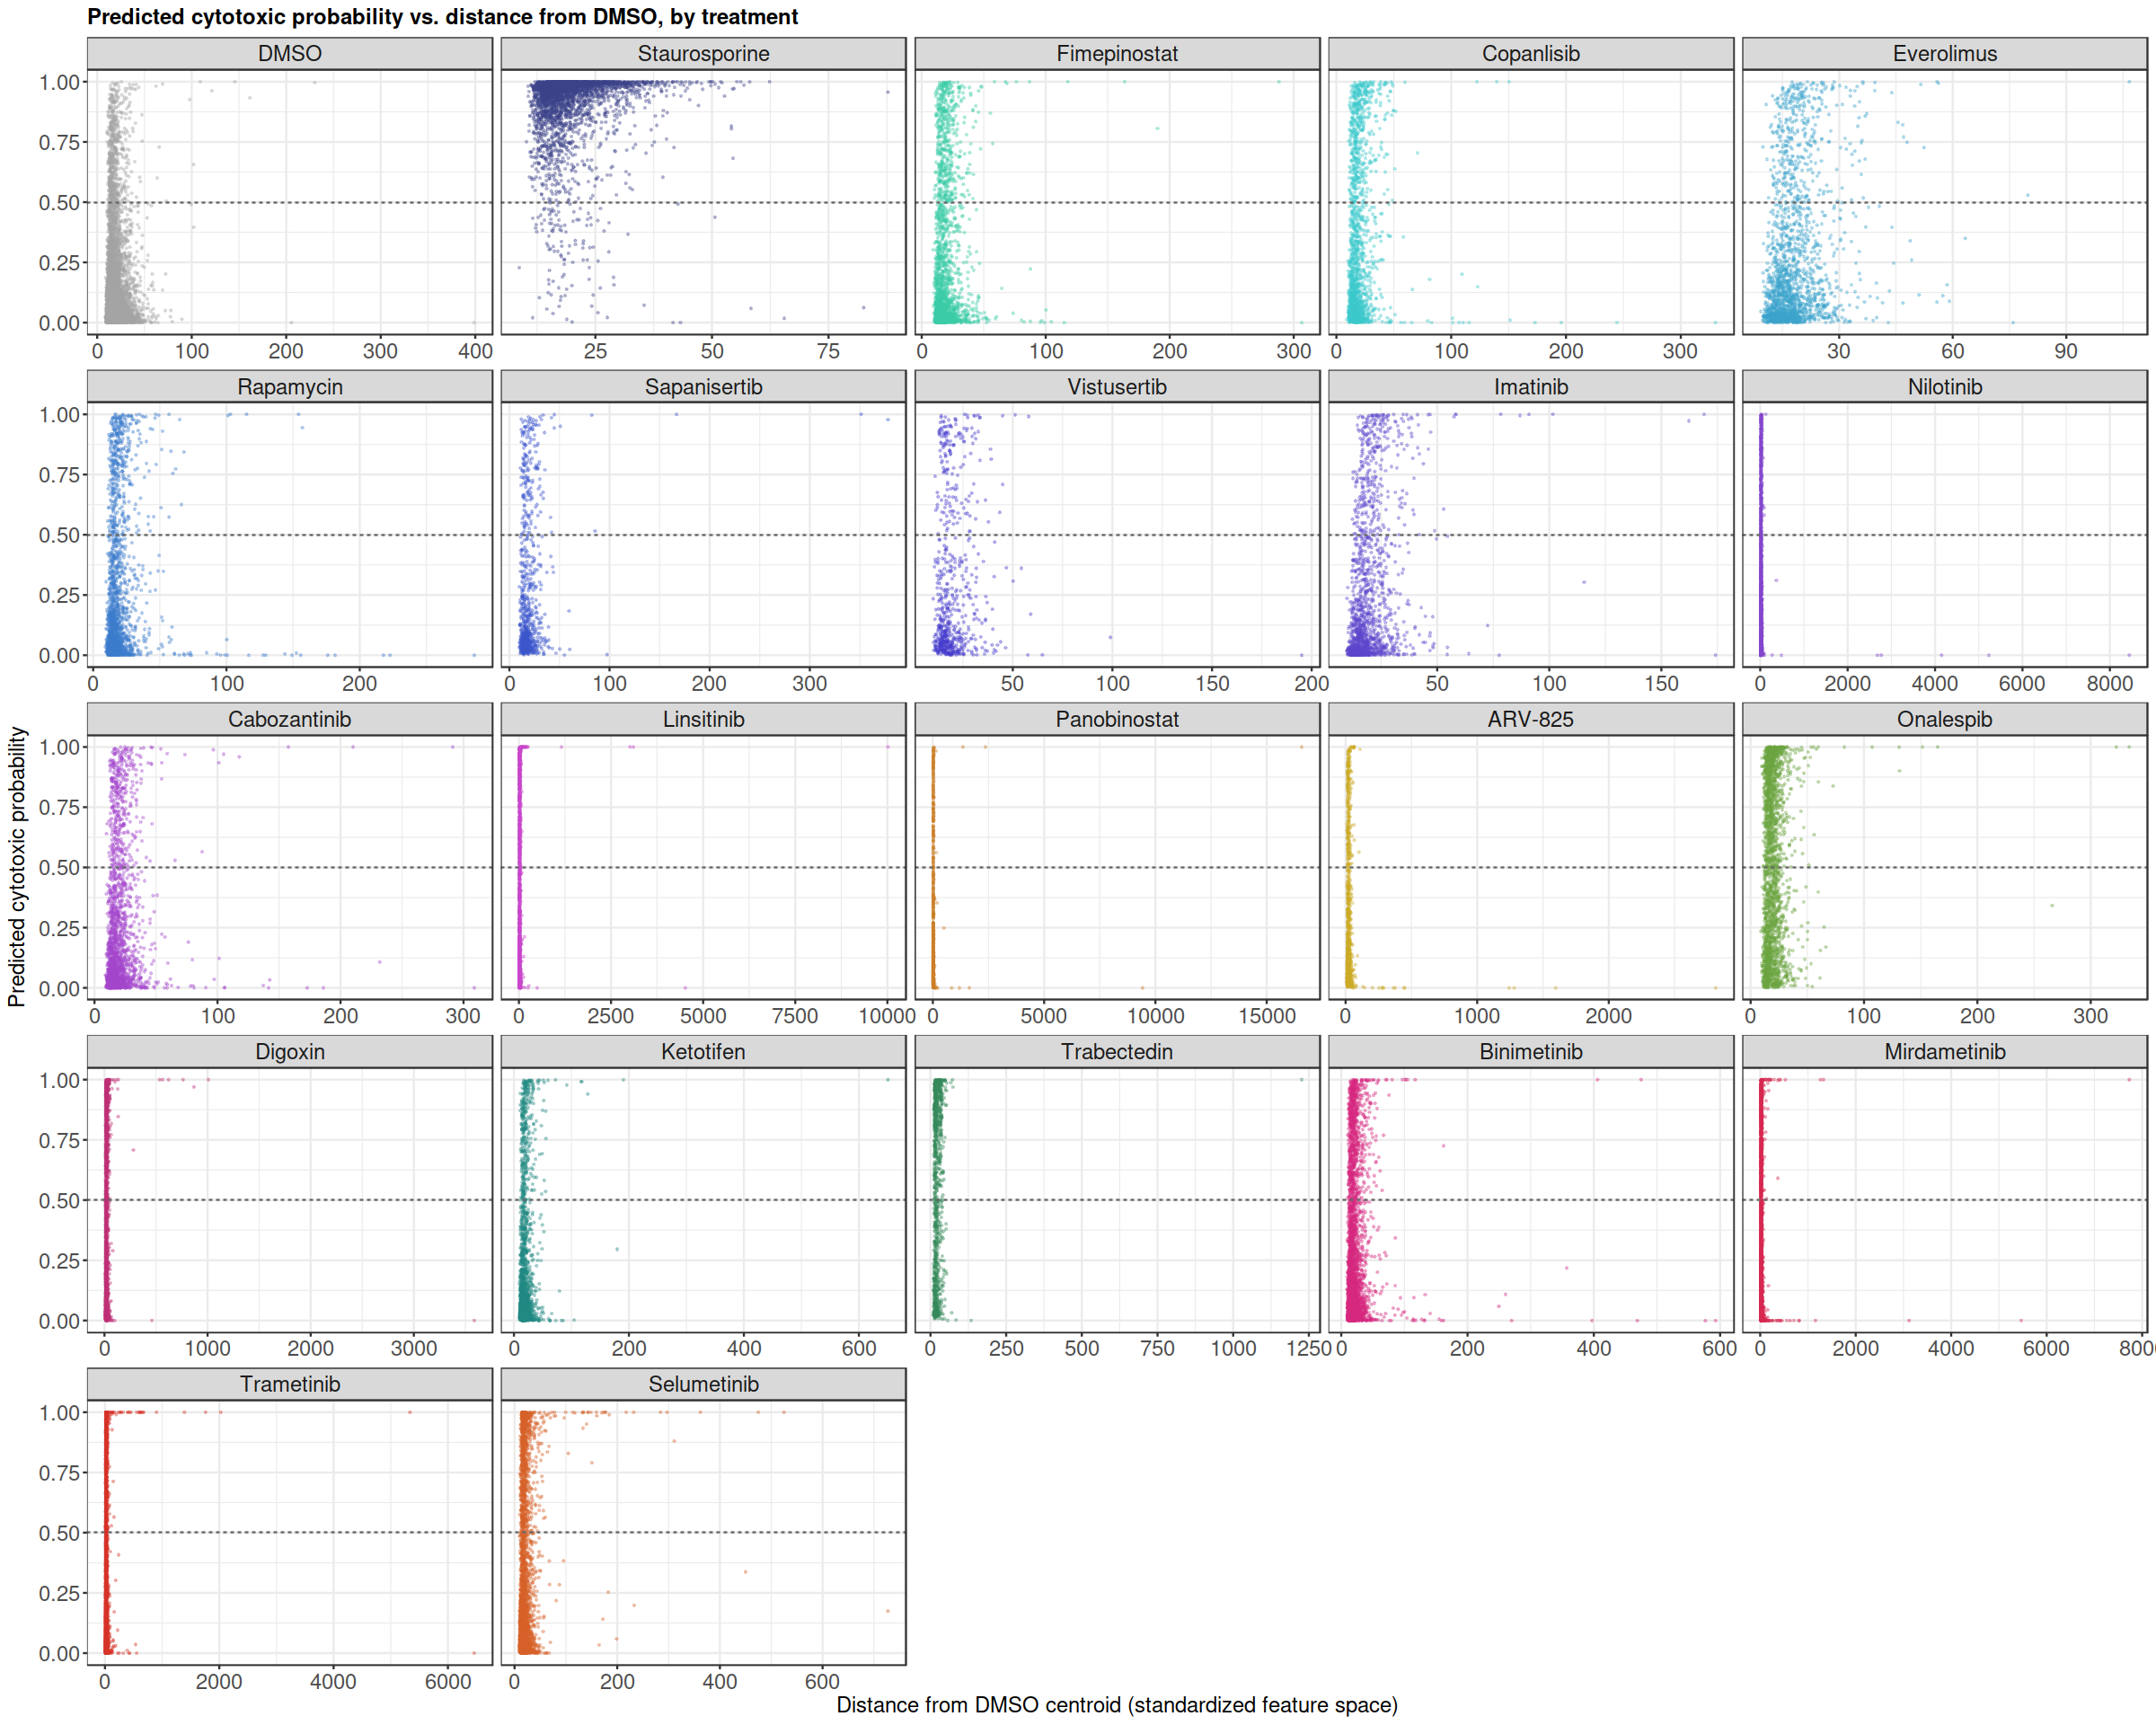

In [5]:
options(repr.plot.width = 20, repr.plot.height = 16)

probability_vs_distance_plot <- (
    ggplot(
        inference_df,
        aes(
            x = Metadata_distance_from_dmso_centroid,
            y = Metadata_predicted_cytotoxic_probability,
            colour = Metadata_Experiment_Treatment
        )
    )
    + rasterise(geom_point(size = 0.4, alpha = 0.3), dpi = 600)
    + geom_hline(yintercept = 0.5, linetype = "dashed", colour = "grey40")
    + scale_colour_manual(values = custom_treatment_palette, guide = "none")
    + facet_wrap(~Metadata_Experiment_Treatment, scales = "free_x")
    + labs(
        x = "Distance from DMSO centroid (standardized feature space)",
        y = "Predicted cytotoxic probability",
        title = "Predicted cytotoxic probability vs. distance from DMSO, by treatment"
    )
    + theme_manuscript(base_size = 14, x_text = "default")
)

ggsave(
    scatter_figure_path, probability_vs_distance_plot,
    width = 20, height = 16, dpi = 600, bg = "white"
)
probability_vs_distance_plot

## 3. Patient x treatment heatmap of mean predicted cytotoxic probability
Rows are patients (only patients with a trained classifier are scored - see `1.train_binary_mlp_control.ipynb`), columns are treatments.

Warning message:
“Vectorized input to `element_text()` is not officially supported.
ℹ Results may be unexpected or may change in future versions of ggplot2.”


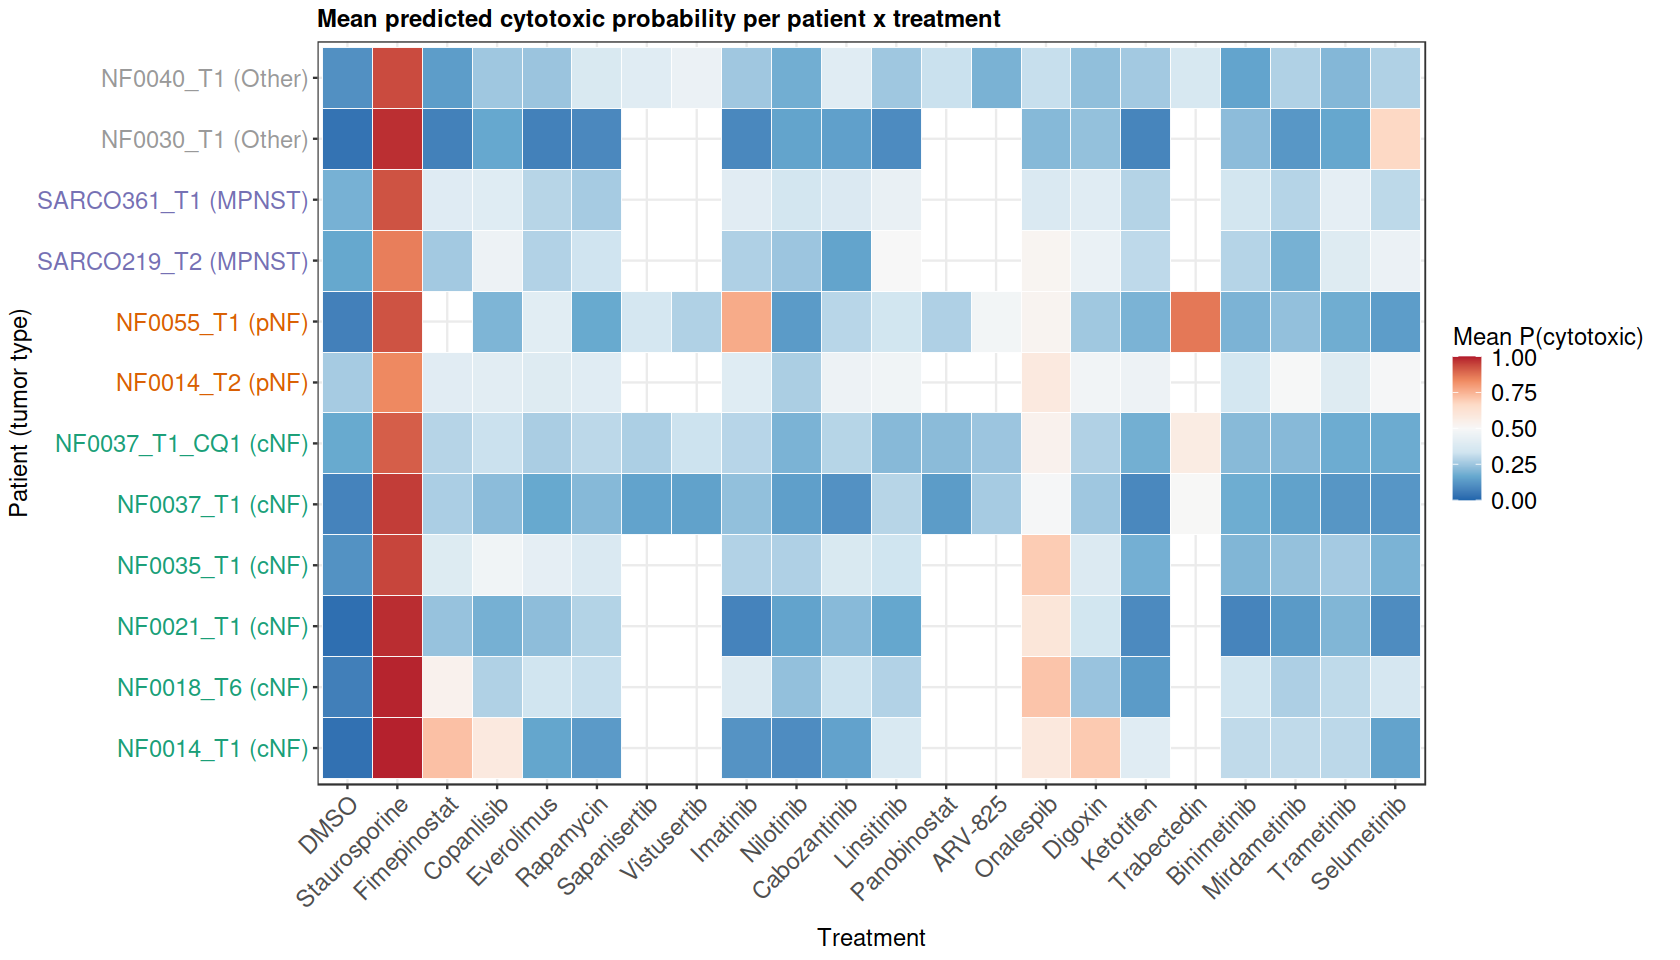

In [6]:
options(repr.plot.width = 14, repr.plot.height = 8)

per_patient_treatment_summary_df$Metadata_Biology_TumorType <- tumor_type_lookup[
    as.character(per_patient_treatment_summary_df$Metadata_Biology_PatientTumor)
]
per_patient_treatment_summary_df$patient_label <- paste0(
    per_patient_treatment_summary_df$Metadata_Biology_PatientTumor,
    " (", per_patient_treatment_summary_df$Metadata_Biology_TumorType, ")"
)

patient_order_df <- per_patient_treatment_summary_df %>%
    distinct(Metadata_Biology_PatientTumor, Metadata_Biology_TumorType, patient_label) %>%
    arrange(
        match(Metadata_Biology_TumorType, names(tumor_type_palette)),
        Metadata_Biology_PatientTumor
    )
per_patient_treatment_summary_df$patient_label <- factor(
    per_patient_treatment_summary_df$patient_label, levels = patient_order_df$patient_label
)

heatmap_plot <- (
    ggplot(
        per_patient_treatment_summary_df,
        aes(
            x = Metadata_Experiment_Treatment,
            y = patient_label,
            fill = Metadata_predicted_cytotoxic_probability_mean
        )
    )
    + geom_tile(colour = "white")
    + scale_fill_distiller(
        palette = "RdBu", direction = -1, limits = c(0, 1), name = "Mean P(cytotoxic)"
    )
    + labs(
        x = "Treatment",
        y = "Patient (tumor type)",
        title = "Mean predicted cytotoxic probability per patient x treatment"
    )
    + theme_manuscript(base_size = 14, x_text = "angled")
    + theme(
        axis.text.y = element_text(
            colour = tumor_type_palette[patient_order_df$Metadata_Biology_TumorType]
        )
    )
)

ggsave(
    heatmap_figure_path, heatmap_plot,
    width = 14, height = 8, dpi = 600, bg = "white"
)
heatmap_plot